In [1]:
import pandas as pd
import math
from sys import float_info
import os
from scipy.stats import spearmanr, linregress, ttest_rel
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def lk_to_dict(lk): 
    lk_arr = lk.strip("[]").split("], [")
    dict = {}
    for l in lk_arr: 
        key, val = l.split(", ")
        dict[int(key)] = float(val)
    return(dict)
def loss_from_df(df): 
    correct_labels = df["correct"]
    answer = df["answer"]
    likelihoods = df["likelihoods"]
    eval_loss = 0
    count = 0
    curr_iter = -1
    prob = 1
    losses = []
    tokens = []
    curr_tokens = []
    for label, iter, lk in zip(correct_labels, answer, likelihoods):  
        lbl, atkn = label.strip("[]").split(",")
        lk_dict = lk_to_dict(lk)
        if curr_iter == -1: 
            curr_iter = iter
        if curr_iter == iter : 
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob *= p
            curr_tokens.append([lbl, atkn])
        else: 
            if prob == 0: 
                    eval_loss += -math.log(float_info.min)
                    losses.append(-math.log(float_info.min))
            else:
                    eval_loss += -math.log(prob)
                    losses.append(-math.log(prob))
            tokens.append(curr_tokens)
            curr_tokens = [[lbl, atkn]]
            count += 1
            p = lk_dict[int(lbl)] if atkn == " None" else lk_dict[int(lbl)]+lk_dict[int(atkn)] 
            prob = p
            curr_iter = iter
   
    if prob == 0: 
        eval_loss += -math.log(float_info.min)
        losses.append(-math.log(float_info.min))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    elif prob != 1:
        eval_loss += -math.log(prob)
        losses.append(-math.log(prob))
        count += 1
        tokens.append(curr_tokens)
        curr_tokens = []
    count += 1
    tokens.append(curr_tokens)
    curr_tokens = []
    return(losses, tokens)


In [3]:
def get_values(study, model, variant = "whole_runs"):
    result_dict = {"study": [],"model": [],  "participant": [], "trial_num": [], "tokens": [], "loss": [] }
    for trial_file in os.listdir(f"full_results/{model}/{study}"):
        trial_df = pd.read_csv(f"full_results/{model}/{study}/{trial_file}")
        losses, tokens = loss_from_df(trial_df)
        part = trial_file.split("_")[-1].split(".")[0]
        i = 0
        for loss, token_arr in (zip(losses,tokens)):
            result_dict["loss"].append(loss)
            result_dict["participant"].append(part)
            result_dict["tokens"].append(token_arr)
            result_dict["study"].append(study)
            result_dict["model"].append(model)
            i+= 1
            result_dict["trial_num"].append(i)
    return(result_dict)

In [ ]:
studies = ["Ajami18", "Bauer19", "Börstler16", "Buse10", "Gopstein17a", "Gopstein17b", "Katzmarski12", "Medeiros19", "Siegmund17", "Peitek18"]
result_dict = {"study": [], "model": [], "participant": [], "trial_num": [], "tokens": [], "loss": [] }
models = ["Centaur", "Llama"]
for study in studies:
    for model in models: 
        res_dict = get_values(study, model)
        for key in result_dict: 
            result_dict[key] = result_dict[key] + res_dict[key]
result_df = pd.DataFrame(result_dict)

In [5]:
def get_correlations(study, df):
    correlations = {}
    linregs = {}
    for model in ["Centaur", "Llama"]:
        model_data = df[df["model"] == model]
        study_data = model_data[model_data["study"] == study]
        trial_nums = []
        losses = []
        for i in range(len(study_data)):
            losses.append(study_data["loss"].iloc[i])
            trial_nums.append(study_data["trial_num"].iloc[i])
        correlation = spearmanr(losses, trial_nums)
        print(f"{model} correlation: {correlation}")
        correlations[model] = correlation
        linreg = linregress(trial_nums, losses)
        linregs[model] = linreg
        plt.plot(trial_nums, losses, "+")
        plt.title(f"trial-loss correlation {model} {study}")
        plt.show()
        plt.close()
    return correlations, linregs


In [6]:
def get_losses(study, df, model): 
    model_data = df[df["model"] == model]
    study_data = model_data[model_data["study"] == study]
    losses = []
    ids = []
    for i in range(len(study_data)):
        losses.append(study_data["loss"].iloc[i])
        ids.append([study_data["participant"].iloc[i], study_data["trial_num"].iloc[i]])
    return losses, ids

def evaluate_study(study, df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses, ids = get_losses(study, df, model)
        ids_arrs.append(ids)
        losses_dict[model] = losses
        res_dict[f"{model}_mean"] = np.mean(losses)
        res_dict[f"{model}_std"] = np.std(losses)
    print(study)
    print(len(losses_dict["Centaur"]), len(losses_dict["Llama"]))
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = study
    return(res_dict)

def eval_all(df):
    res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
    ids_arrs = []
    losses_dict = {"Centaur": [], "Llama": []}
    for model in ["Centaur", "Llama"]: 
        losses_all = []
        ids_all = []
        for study in studies:
            losses, ids = get_losses(study, df, model)
            losses_all += losses
            ids_all+= ids
        ids_arrs.append(ids_all)
        print(len(losses_all))
        losses_dict[model] = losses_all
        res_dict[f"{model}_mean"] = np.mean(losses_all)
        res_dict[f"{model}_std"] = np.std(losses_all)
    ttest = ttest_rel(losses_dict["Centaur"], losses_dict["Llama"])
    res_dict["tstat"] = ttest.statistic
    res_dict["pvalue"] = ttest.pvalue
    diff = np.array(losses_dict["Centaur"]) - np.array(losses_dict["Llama"])
    cohen_d = ttest.statistic/math.sqrt(len(diff))
    res_dict["cohen_d"] = cohen_d
    if len(ids_arrs[0]) != len(ids_arrs[1]): 
        print("Mismatch, length difference")
    else: 
        res_dict["trials"] = len(losses_all)
    for id1, id2 in zip(ids_arrs[0], ids_arrs[1]): 
        if id1 != id2: 
            print(f"Mismatch, {id1} and {id2} are unequal")
    res_dict["study"] = "overall"
    return(res_dict)
    

In [7]:
present = []
expected = list(range(1,413))
for file in os.listdir("full_results/Centaur/Katzmarski12"):
    num = int(file.split("_")[-1].split(".")[0])
    present.append(num)
for val in expected: 
    if not val in present: 
        print(f"missing {val}")

In [8]:
all_res_dict = {"study": [], "trials": [], "Centaur_mean":[], "Centaur_std": [], "Llama_mean": [], "Llama_std": [], "tstat": [], "pvalue": [], "cohen_d": []}
for study in studies: 
    study_res_dict = evaluate_study(study, result_df)
    for key in all_res_dict:
        all_res_dict[key].append(study_res_dict[key])
study_res_dict = eval_all(result_df)
for key in study_res_dict:
    all_res_dict[key].append(study_res_dict[key])
all_res_df = pd.DataFrame(all_res_dict)
all_res_df.to_csv("results/results_RQ1.csv", index=False)
result_df.to_csv("results/data_RQ1.csv", index=False)

Ajami18
2067 2067
Bauer19
88 88
Börstler16
2598 2598
Buse10
12100 12100
Gopstein17a
6069 6069
Gopstein17b
498 498
Katzmarski12
3708 3708
Medeiros19
1164 1164
Peitek17
420 420
Peitek18b
550 550
29262
29262


Ajami18: 2067 Trials
Centaur mean: 0.8069995230746505, STD: 1.40301670132209
Llama mean: 0.889273986487128, STD: 1.7935893542452712
T-test statistic: -4.08598499660055, p-value: 4.55669447002904e-05, cohen's d: -0.08987243928066489


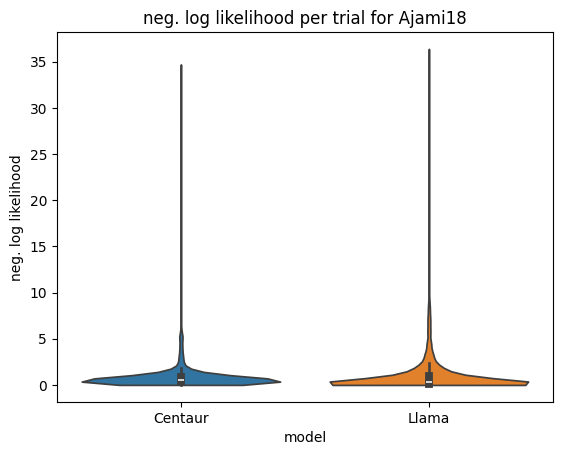

Bauer19: 88 Trials
Centaur mean: 4.396451625617046, STD: 2.971122937066707
Llama mean: 5.4111677307355555, STD: 4.428127993900835
T-test statistic: -5.64744825741584, p-value: 2.0132810474584427e-07, cohen's d: -0.6020200070311504


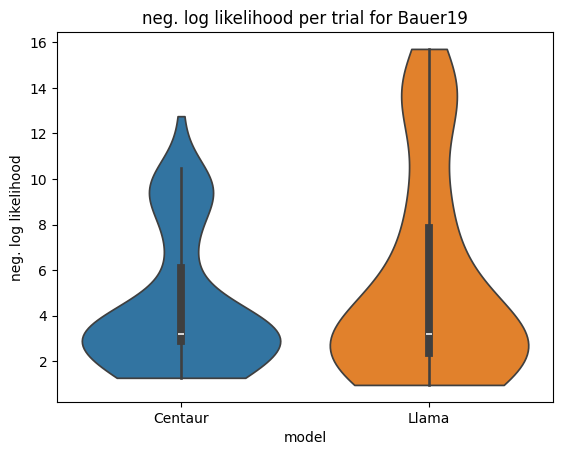

Börstler16: 2598 Trials
Centaur mean: 4.268380960238486, STD: 6.249215581464621
Llama mean: 4.873256695398825, STD: 7.102482079147356
T-test statistic: -10.219527945527028, p-value: 4.597534502930982e-24, cohen's d: -0.20049856202837388


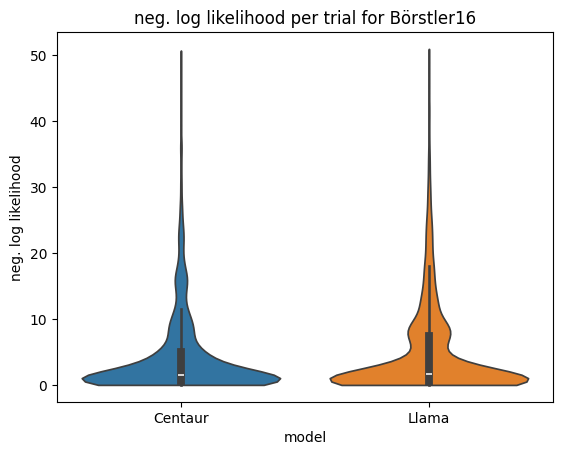

Buse10: 12100 Trials
Centaur mean: 1.395943047459524, STD: 0.715485700083144
Llama mean: 1.5644936273754197, STD: 1.071163273978311
T-test statistic: -25.224939029537644, p-value: 7.095487518770601e-137, cohen's d: -0.22931762754125132


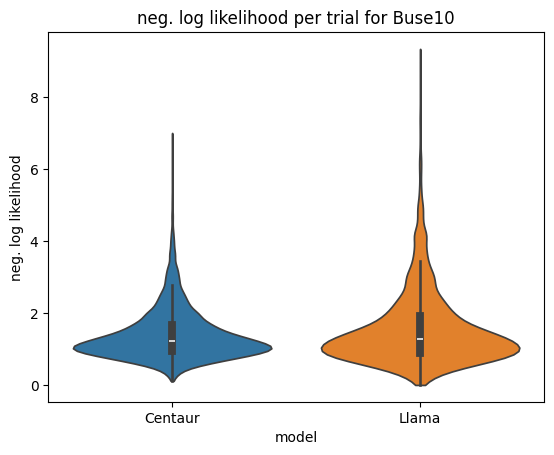

Gopstein17a: 6069 Trials
Centaur mean: 1.3150067042704492, STD: 2.181633618033645
Llama mean: 1.545423176881732, STD: 2.8135066789798318
T-test statistic: -14.04891807644183, p-value: 3.824048986478842e-44, cohen's d: -0.18033678016114307


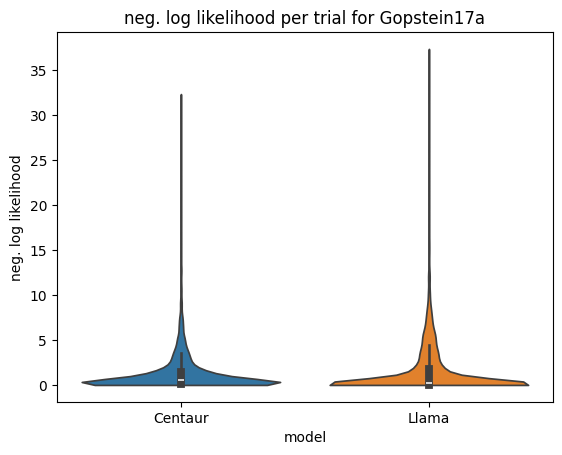

Gopstein17b: 498 Trials
Centaur mean: 4.158951223874353, STD: 3.349996740204988
Llama mean: 4.243332769361387, STD: 3.503291189099371
T-test statistic: -1.1172817642412418, p-value: 0.2644136831093775, cohen's d: -0.050066593017275236


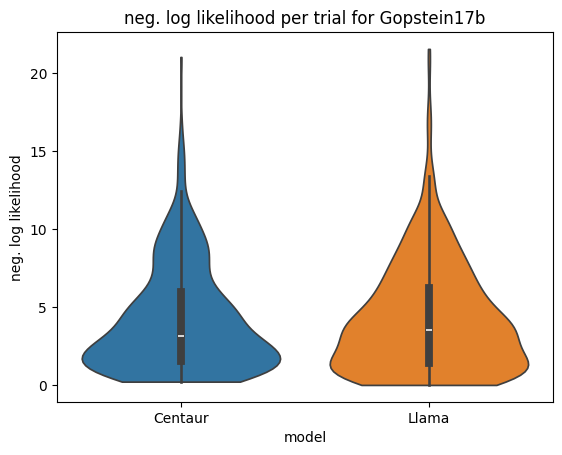

Katzmarski12: 3708 Trials
Centaur mean: 1.408357563546581, STD: 1.2151586471156195
Llama mean: 1.7243043468518404, STD: 1.8146028851210785
T-test statistic: -19.687542494242614, p-value: 3.781933549270631e-82, cohen's d: -0.323311867244682


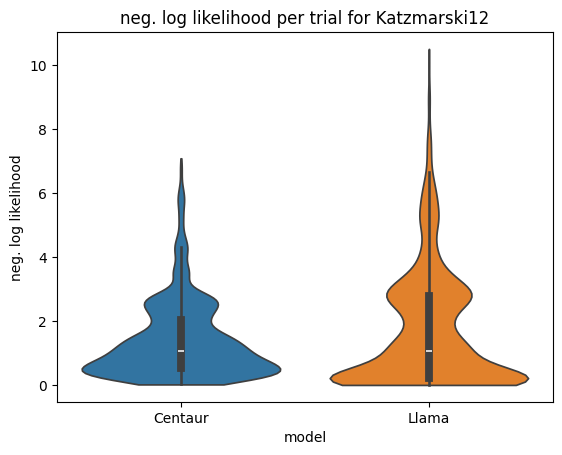

Medeiros19: 1164 Trials
Centaur mean: 1.6236087388847626, STD: 0.6901093751999617
Llama mean: 1.5577137663338618, STD: 1.0709590909465596
T-test statistic: 2.158577985869524, p-value: 0.031087000816931602, cohen's d: 0.06326904125782455


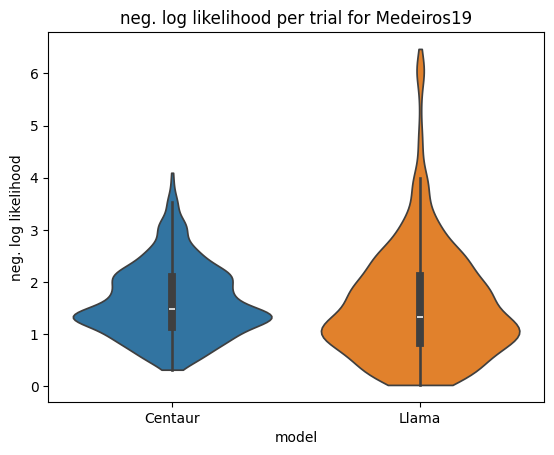

Peitek17: 420 Trials
Centaur mean: 0.4614202373385271, STD: 0.9331033323015755
Llama mean: 0.6198657471829877, STD: 1.4462028919852963
T-test statistic: -4.533912996534203, p-value: 7.567329345000361e-06, cohen's d: -0.22123230120300155


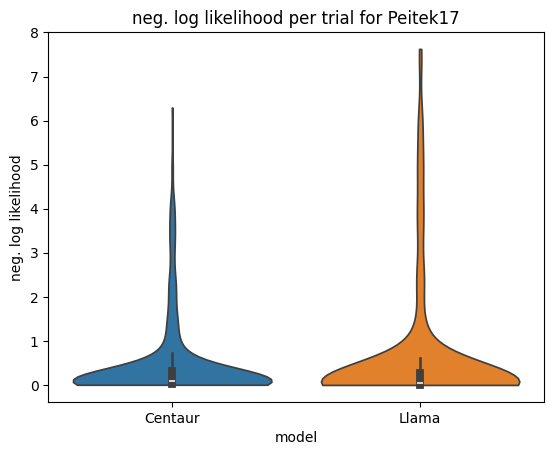

Peitek18b: 550 Trials
Centaur mean: 0.5303997833605949, STD: 0.8831842418944529
Llama mean: 0.6367599953853689, STD: 1.330873210247119
T-test statistic: -4.207218323845051, p-value: 3.0194976337968507e-05, cohen's d: -0.1793963921016431


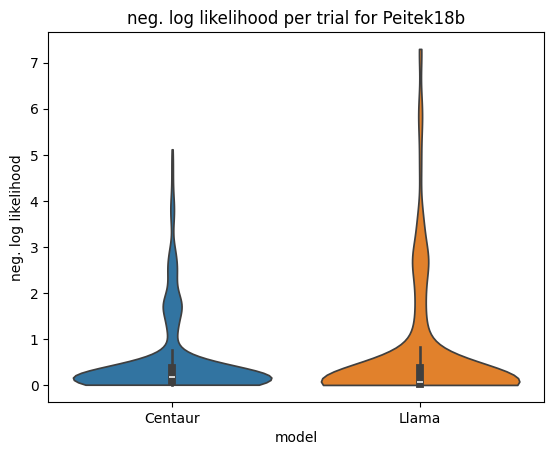

overall: 29262 Trials
Centaur mean: 1.6295755779556869, STD: 2.478990958693311
Llama mean: 1.8527516850973138, STD: 2.955714898163397
T-test statistic: -29.40045927562296, p-value: 2.8780991731782045e-187, cohen's d: -0.1718708052587146


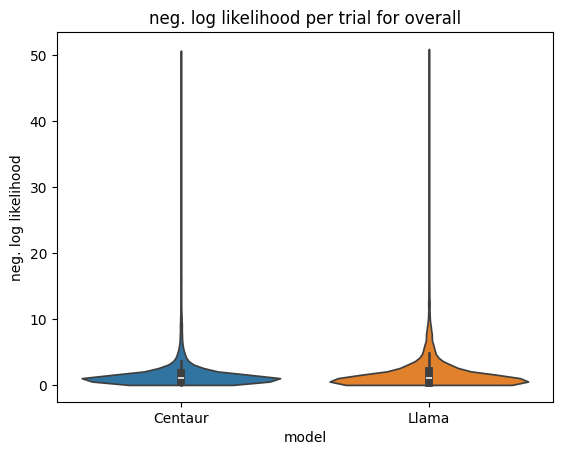

In [9]:
#TODO Violinplots & Eval
import seaborn as sns
variant = "RQ1"
for study in studies: 
    study_data_df = result_df[result_df["study"]==study]
    study_result_df = all_res_df[all_res_df["study"]==study]
    print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
    print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
    print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
    print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
    sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
    plt.ylabel("neg. log likelihood")
    plt.title(f"neg. log likelihood per trial for {study}")
    plt.savefig(f"images/{study}_violin_{variant}.png")
    plt.show()
    plt.close()
study = "overall"
study_data_df = result_df
study_result_df = all_res_df[all_res_df["study"]==study]
print(f"{study_result_df['study'].iloc[0]}: {study_result_df['trials'].iloc[0]} Trials") 
print(f"Centaur mean: {study_result_df['Centaur_mean'].iloc[0]}, STD: {study_result_df['Centaur_std'].iloc[0]}")
print(f"Llama mean: {study_result_df['Llama_mean'].iloc[0]}, STD: {study_result_df['Llama_std'].iloc[0]}")
print(f"T-test statistic: {study_result_df['tstat'].iloc[0]}, p-value: {study_result_df['pvalue'].iloc[0]}, cohen's d: {study_result_df['cohen_d'].iloc[0]}")
sns.violinplot(study_data_df, x = "model", y = "loss", hue = "model", cut=0)
plt.ylabel("neg. log likelihood")
plt.title(f"neg. log likelihood per trial for {study}")
plt.savefig(f"images/{study}_violin_{variant}.png")
plt.show()
plt.close()